# TED 03 - Modelagem Preditiva e Machine Learning
**Projeto:** IAnjos de Patas · **Base:** PetFinder.my mini (mesma base tratada na TED 02)

**Pergunta:** uma descrição textual permite classificar corretamente se um anúncio se refere a um gato ou a um cão? O experimento apoia testes de consistência de cadastro, e **não comprova compatibilidade com famílias ou comportamento**.

## 1. Decisões metodológicas
- **Entrada:** `Description` (texto, principalmente em inglês). **Alvo:** `Type` (`Cat`/`Dog`).
- 9 textos vazios ficam fora do classificador; seus perfis permanecem na base original tratada.
- Textos idênticos, após normalização, são alocados ao mesmo conjunto; evitamos o mesmo texto em treino e teste.
- `StratifiedGroupKFold` separa treino/validação/teste, com semente 42.
- A vetorização TF-IDF é ajustada **somente nos dados de treino**.
- Comparação com classe majoritária, Naive Bayes e Regressão Logística; seleção por **F1 macro na validação**. Teste só ao final.

In [1]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve()
for pasta in [ROOT, *ROOT.parents]:
    if (pasta / 'src' / 'ted03.py').exists():
        ROOT = pasta
        break
else:
    raise FileNotFoundError('Abra o notebook dentro do projeto IAnjos_Petfinder.')

dados = pd.read_csv(ROOT / 'data/processed/petfinder_mini_tratado.csv', encoding='utf-8-sig')
print('Base TED02:', dados.shape)
print('Descrições ausentes:', dados['Description'].isna().sum())
print(dados['Type'].value_counts())

Base TED02: (11537, 21)
Descrições ausentes: 9
Type
Dog    6601
Cat    4936
Name: count, dtype: int64


## 2. Executar o treinamento e a avaliação
O script `src/ted03.py` reúne a rotina completa. Chamá-lo aqui mantém os mesmos critérios para Git, VS Code e notebook e grava resultados rastreáveis em `reports/TED03`.

In [2]:
import subprocess, sys, os
processo = subprocess.run([sys.executable, str(ROOT / 'src/ted03.py')],
                         cwd=ROOT, capture_output=True, text=True, encoding='utf-8',
                         env={**os.environ, 'PYTHONIOENCODING': 'utf-8'}, check=True)
print(processo.stdout)

{
  "modelo_selecionado": "Regressão Logística + TF-IDF",
  "validacao_f1_macro": 0.9106507261247343,
  "teste_f1_macro": 0.9256966657755736,
  "teste_acuracia": 0.9270516717325228,
  "baseline_f1_macro": 0.3641634456101601,
  "tamanhos": {
    "treino": {
      "total": 8074,
      "Gato": 3453,
      "Cão": 4621,
      "descricoes_distintas": 7528
    },
    "validacao": {
      "total": 1151,
      "Gato": 492,
      "Cão": 659,
      "descricoes_distintas": 1052
    },
    "teste": {
      "total": 2303,
      "Gato": 984,
      "Cão": 1319,
      "descricoes_distintas": 2091
    },
    "treino_final": {
      "total": 9225,
      "Gato": 3945,
      "Cão": 5280,
      "descricoes_distintas": 8580
    }
  }
}



## 3. Resultados em métricas
A **acurácia** mede o percentual total de acertos; **precisão** indica a qualidade das previsões de uma classe; **recall** identifica a proporção recuperada; **F1 macro** dá peso igual a gatos e cães. A **matriz de confusão** indica a natureza dos erros. As métricas de teste não foram utilizadas para selecionar o algoritmo.

In [3]:
import json, pandas as pd
r = json.loads((ROOT / 'reports/TED03/resultados.json').read_text(encoding='utf-8'))
print('Modelo selecionado:',r['modelo_selecionado'])
print('Distribuição:',r['distribuicao'])
pd.DataFrame([{'modelo':k,'acurácia validação':v['accuracy'],'F1 macro validação':v['f1_macro']} for k,v in r['validacao'].items()]).round(4)

Modelo selecionado: Regressão Logística + TF-IDF
Distribuição: {'treino': {'total': 8074, 'Gato': 3453, 'Cão': 4621, 'descricoes_distintas': 7528}, 'validacao': {'total': 1151, 'Gato': 492, 'Cão': 659, 'descricoes_distintas': 1052}, 'teste': {'total': 2303, 'Gato': 984, 'Cão': 1319, 'descricoes_distintas': 2091}, 'treino_final': {'total': 9225, 'Gato': 3945, 'Cão': 5280, 'descricoes_distintas': 8580}}


,modelo,acurácia validação,F1 macro validação
0,Maioria (baseline),0.5725,0.3641
1,Naive Bayes + TF-IDF,0.8940,0.8882
2,Regressão Logística + TF-IDF,0.9123,0.9107


In [4]:
pd.DataFrame([{'modelo':k,'acurácia teste':v['accuracy'],'F1 macro teste':v['f1_macro']} for k,v in r['teste'].items()]).round(4)

,modelo,acurácia teste,F1 macro teste
0,modelo_selecionado,0.9271,0.9257
1,baseline_maioria,0.5727,0.3642
2,teste_com_termos_de_especie_ocultos,0.8419,0.8379


## 4. Gráficos e interpretação
Os gráficos são produzidos diretamente das previsões obtidas no teste, não são ilustrações inventadas. A comparação de algoritmos usa validação, enquanto a matriz de confusão usa somente teste.

01_divisao_dados.png
02_comparacao_validacao.png
03_matriz_confusao.png
04_metricas_por_classe.png


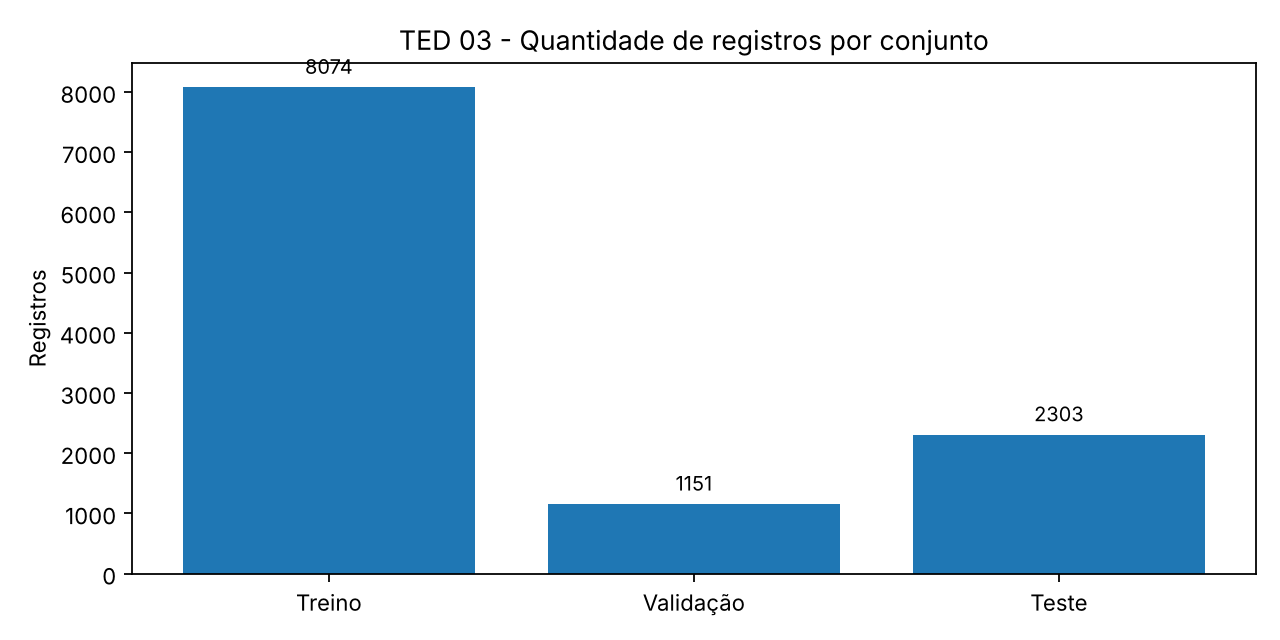

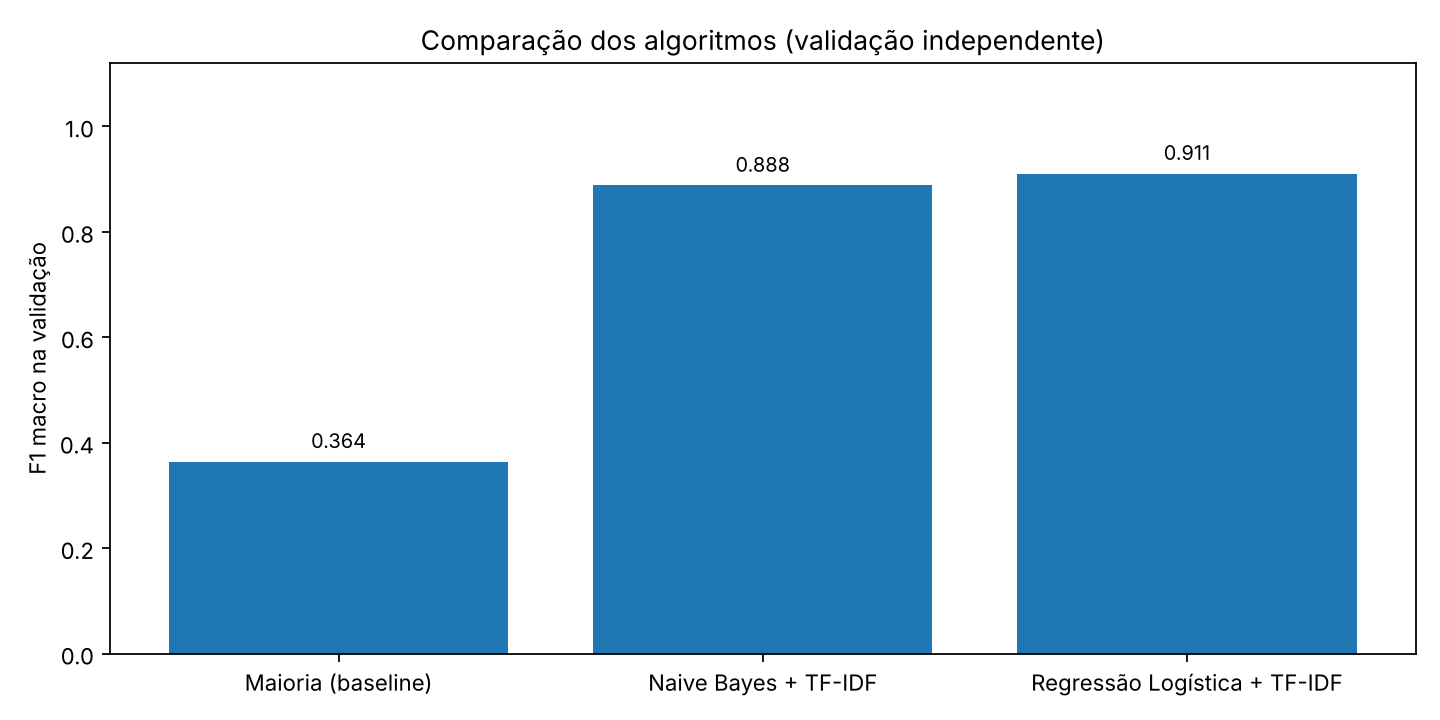

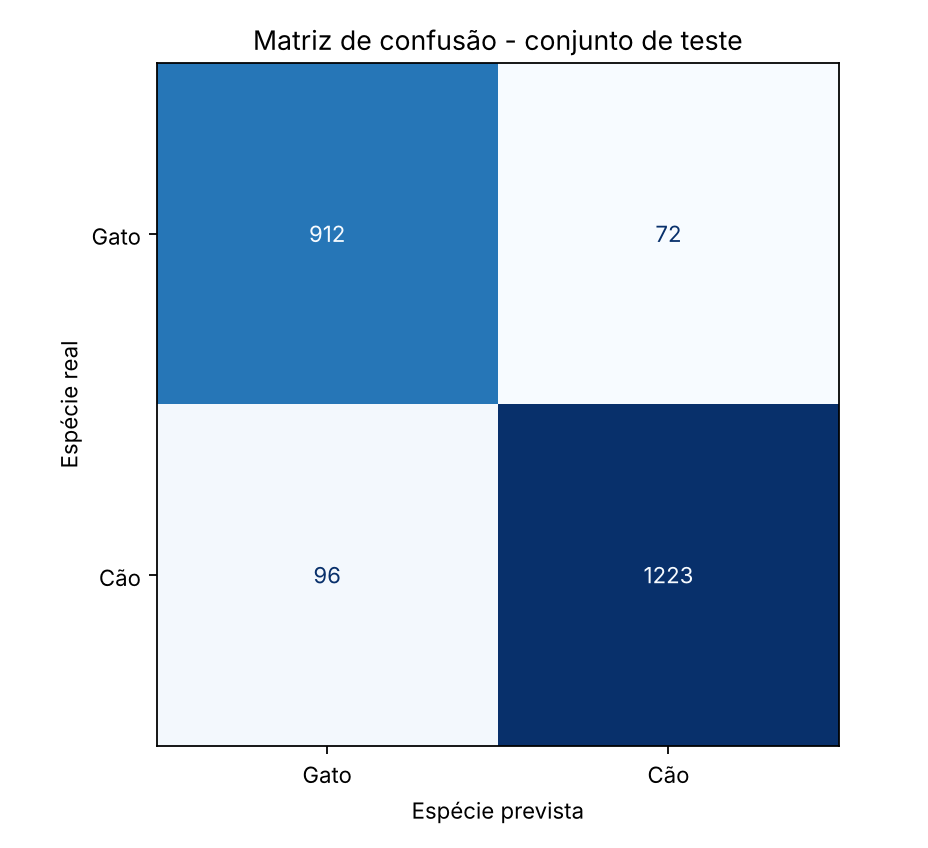

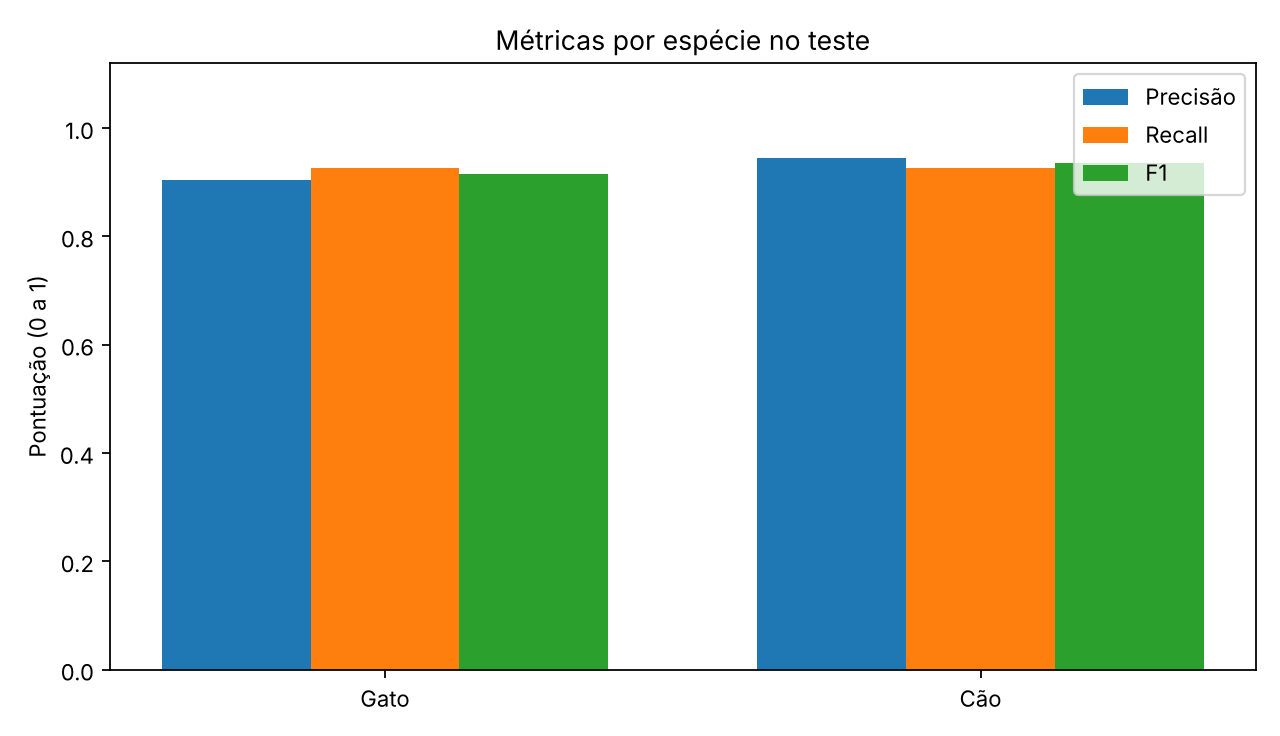

In [5]:
from IPython.display import display, Image
fig = ROOT / 'reports/TED03/figures'
for arquivo in sorted(fig.glob('*.png')):
    print(arquivo.name)
    display(Image(filename=str(arquivo),width=700))

## 5. Limitações e conexão com o MVP
A base é histórica, estrangeira e não demonstra condições atuais de adoção. Textos podem conter as próprias palavras `cat`, `dog`, `puppy` etc.; nesse cenário a classificação é mais fácil do que prever espécie em descrições ambíguas. Há descrições curtas e multilingues e grupos de descrições idênticas com rótulos diferentes. O experimento adicional que oculta palavras de espécie é **diagnóstico sob mudança artificial de entrada**, não uma nova avaliação independente.

**Aplicabilidade:** apoio experimental à verificação de cadastros. O MVP continua dependente de dados cadastrados e validados e da interpretação de frases em português. Não usar como inferência de temperamento, saúde ou adequação à família. Para afirmar que melhora o chatbot, será preciso uma avaliação com consultas em português e respostas esperadas revisadas por pessoas.